<a href="https://colab.research.google.com/github/tikakukeko/Studi_Kasus_Dan_Implementasi_Kode_Atikah_Putri_Utami_G1A024027/blob/main/Studi_Kasus_Bridging_Global_Infrastructure_to_Address_Local_Challenges_in_High_Performance_Computing_(HPC).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## Studi Kasus Lengkap: Konteks Lingkungan, Analisis, dan Interpretasi

### A. Latar belakang
Partikel halus PM2.5 merupakan salah satu indikator kualitas udara yang penting untuk dipantau. Konsentrasi partikel dapat dipengaruhi banyak faktor, antara lain aktivitas lalu lintas, kondisi meteorologi, sumber emisi, dan karakteristik wilayah. Analisis data dan Machine Learning dapat digunakan untuk mempelajari pola, tetapi model yang baik membutuhkan pengukuran lapangan yang representatif dan validasi yang benar.

### B. Rumusan masalah
1. Bagaimana karakteristik fitur yang digunakan dalam dataset?
2. Seberapa dekat prediksi model dengan nilai target pada data uji?
3. Bagaimana membaca MAE, RMSE, dan R²?
4. Apa yang diperlukan sebelum pendekatan ini digunakan pada data kualitas udara nyata?

### C. Tujuan
- Menyusun dan memeriksa dataset contoh.
- Melatih Random Forest Regressor untuk memprediksi target PM2.5.
- Mengukur kesalahan prediksi menggunakan MAE dan RMSE serta kecocokan menggunakan R².
- Membandingkan nilai aktual dan prediksi secara visual.
- Memahami batas antara demonstrasi model dan prakiraan operasional.

### D. Penjelasan fitur dan target
- `temperature_c`: suhu dalam derajat Celsius.
- `humidity_pct`: kelembapan relatif dalam persen.
- `wind_speed_ms`: kecepatan angin dalam meter per detik.
- `traffic_index`: indeks lalu lintas simulasi, bukan satuan baku universal.
- `pm25`: target PM2.5 simulasi, biasanya dinyatakan dalam µg/m³ pada konteks pengukuran.

Pada notebook ini, target dibuat menggunakan rumus buatan untuk demonstrasi. Karena itu, hubungan yang ditemukan model terutama mencerminkan cara data sintetis dibuat, bukan bukti ilmiah mengenai faktor penyebab PM2.5.

### E. Metodologi
1. **Pembuatan data:** membuat 500 baris data sintetis agar contoh dapat berjalan tanpa mengunduh data eksternal.
2. **Pemeriksaan data:** memeriksa dimensi, nilai kosong, dan statistik ringkas.
3. **Pemilihan fitur:** menggunakan empat fitur masukan dan `pm25` sebagai target.
4. **Pembagian data:** 80% untuk pelatihan dan 20% untuk pengujian.
5. **Pelatihan:** menggunakan Random Forest Regressor dengan 150 pohon dan kedalaman maksimum 8.
6. **Evaluasi:** menghitung MAE, RMSE, dan R² pada data uji.
7. **Visualisasi:** membandingkan nilai aktual simulasi dengan prediksi model.
8. **Prediksi contoh:** memasukkan satu observasi baru dengan fitur yang sama.

### F. Cara menginterpretasikan metrik
- **MAE (Mean Absolute Error):** rata-rata selisih absolut antara nilai aktual dan prediksi. Nilai lebih kecil umumnya lebih baik.
- **RMSE (Root Mean Squared Error):** memberi penalti lebih besar pada kesalahan yang besar. Nilai lebih kecil umumnya lebih baik.
- **R²:** membandingkan model dengan baseline berupa prediksi rata-rata target. Nilai mendekati 1 dapat menunjukkan kecocokan yang baik pada data evaluasi; nilai negatif berarti model lebih buruk daripada baseline tersebut pada evaluasi itu.

Jangan menilai model hanya dari satu metrik. Periksa rentang target, pola kesalahan, dan apakah data uji mewakili kondisi penggunaan yang direncanakan.

### G. Membaca grafik aktual vs prediksi
Garis diagonal putus-putus menunjukkan lokasi prediksi ideal ketika nilai prediksi sama dengan nilai aktual. Titik yang dekat garis berarti kesalahan lebih kecil; titik yang jauh berarti kesalahan lebih besar. Pola sistematis—misalnya prediksi selalu terlalu rendah pada nilai tinggi—perlu diselidiki lebih lanjut.

### H. Keterbatasan dan risiko
- Dataset bersifat sintetis, bukan data sensor atau stasiun pemantauan.
- Rumus target disederhanakan dan tidak merepresentasikan proses atmosfer yang kompleks.
- Pembagian acak tidak menguji kemampuan memprediksi periode waktu mendatang.
- Model tidak boleh digunakan sebagai prakiraan resmi atau dasar keputusan kesehatan dan keselamatan.
- Nilai fitur, lokasi, waktu, satuan, kalibrasi sensor, dan data hilang perlu ditangani secara eksplisit pada data nyata.

### I. Pengembangan berikutnya
1. Gunakan data PM2.5 yang memiliki sumber, lokasi, waktu, dan satuan yang jelas.
2. Bandingkan model baseline dengan Random Forest dan model lain.
3. Untuk data berurutan waktu, latih pada periode lebih lama dan uji pada periode sesudahnya.
4. Analisis residual dan performa pada tiap lokasi atau musim.
5. Dokumentasikan versi data, parameter, dan hasil evaluasi.
6. Jika volume data sensor atau model cuaca sangat besar, pertimbangkan komputasi terdistribusi atau HPC; notebook ini sendiri berjalan pada komputasi biasa.

### J. Kesimpulan studi kasus
Notebook memperlihatkan alur dasar regresi Machine Learning untuk memperkirakan target PM2.5 simulasi. Kesimpulan yang sah hanya mengenai demonstrasi metode pada dataset sintetis. Penerapan nyata membutuhkan data pengukuran yang valid, evaluasi berbasis waktu, pembandingan baseline, dan pemeriksaan ahli lingkungan.


## 1. Import library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
print("Library berhasil diimpor.")

Library berhasil diimpor.


## 2. Membuat dataset simulasi


In [2]:
rng = np.random.default_rng(2026)
n = 500

temperature = rng.uniform(20, 36, n)
humidity = rng.uniform(35, 98, n)
wind_speed = rng.uniform(0.2, 8, n)
traffic_index = rng.uniform(5, 100, n)
noise = rng.normal(0, 3, n)

# Rumus sintetis untuk membuat contoh target, bukan rumus ilmiah PM2.5.
pm25 = (
    7
    + 0.22 * traffic_index
    + 0.07 * humidity
    + 0.18 * (temperature - 25)
    - 1.15 * wind_speed
    + noise
)
pm25 = np.clip(pm25, 2, None)

df = pd.DataFrame({
    "temperature_c": np.round(temperature, 2),
    "humidity_pct": np.round(humidity, 2),
    "wind_speed_ms": np.round(wind_speed, 2),
    "traffic_index": np.round(traffic_index, 2),
    "pm25": np.round(pm25, 2),
})

df.to_csv("pm25_sample.csv", index=False)
print(f"Jumlah baris data simulasi: {len(df)}")
df.head()

Jumlah baris data simulasi: 500


,temperature_c,humidity_pct,wind_speed_ms,traffic_index,pm25
0,22.86,89.89,6.47,26.78,11.70
1,30.24,51.79,0.95,60.84,26.92
2,27.48,91.32,5.68,49.31,20.18
3,25.93,54.28,4.70,83.50,20.21
4,25.68,38.61,5.73,82.17,19.83


## 3. Memeriksa data

In [3]:
print("Ukuran dataset:", df.shape)
print("\nJumlah nilai kosong per kolom:")
display(df.isna().sum())

print("\nRingkasan statistik:")
display(df.describe().round(2))

Ukuran dataset: (500, 5)

Jumlah nilai kosong per kolom:


,0
temperature_c,0
humidity_pct,0
wind_speed_ms,0
traffic_index,0
pm25,0



Ringkasan statistik:


,temperature_c,humidity_pct,wind_speed_ms,traffic_index,pm25
count,500.00,500.00,500.00,500.00,500.00
mean,28.00,69.24,4.12,50.99,18.83
std,4.51,18.10,2.28,27.31,7.28
min,20.03,35.09,0.23,5.17,2.00
25%,24.26,53.91,2.15,26.75,13.26
50%,27.96,71.28,4.14,48.93,18.80
75%,31.86,84.49,6.10,74.18,24.52
max,35.99,97.99,7.97,99.94,39.31


## 4. Menentukan fitur dan target

In [4]:
features = [
    "temperature_c",
    "humidity_pct",
    "wind_speed_ms",
    "traffic_index"
]
target = "pm25"

X = df[features]
y = df[target]

print("Fitur:", features)
print("Target:", target)

Fitur: ['temperature_c', 'humidity_pct', 'wind_speed_ms', 'traffic_index']
Target: pm25


## 5. Membagi data latih dan data uji


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Data latih:", X_train.shape[0], "baris")
print("Data uji:", X_test.shape[0], "baris")

Data latih: 400 baris
Data uji: 100 baris


## 6. Melatih model Random Forest

In [6]:
model = RandomForestRegressor(
    n_estimators=150,
    max_depth=8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Model berhasil dilatih.")

Model berhasil dilatih.


## 7. Evaluasi model

In [7]:
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("=== Evaluasi pada dataset simulasi ===")
print(f"MAE : {mae:.3f} µg/m³")
print(f"RMSE: {rmse:.3f} µg/m³")
print(f"R²  : {r2:.3f}")

print("\nCatatan: angka ini hanya mengukur performa pada data sintetis, bukan kondisi udara nyata.")

=== Evaluasi pada dataset simulasi ===
MAE : 2.185 µg/m³
RMSE: 2.797 µg/m³
R²  : 0.852

Catatan: angka ini hanya mengukur performa pada data sintetis, bukan kondisi udara nyata.


## 8. Visualisasi nilai aktual dan prediksi

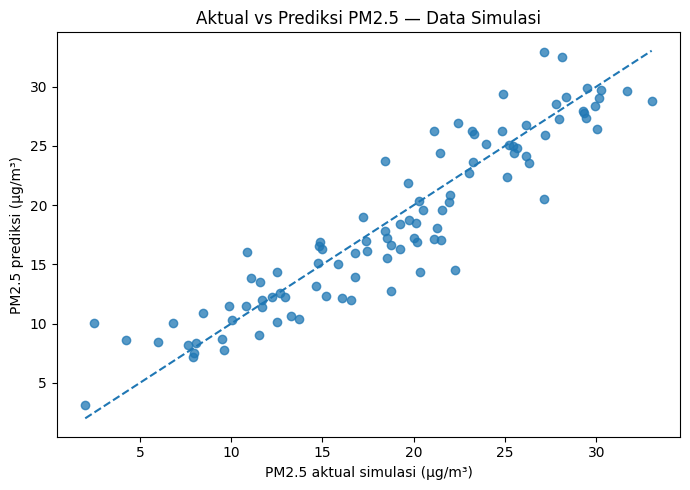

In [8]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.75)

low = min(float(y_test.min()), float(predictions.min()))
high = max(float(y_test.max()), float(predictions.max()))
plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("PM2.5 aktual simulasi (µg/m³)")
plt.ylabel("PM2.5 prediksi (µg/m³)")
plt.title("Aktual vs Prediksi PM2.5 — Data Simulasi")
plt.tight_layout()
plt.show()

## 9. Contoh prediksi untuk data baru

In [9]:
data_baru = pd.DataFrame([{
    "temperature_c": 29.0,
    "humidity_pct": 75.0,
    "wind_speed_ms": 2.0,
    "traffic_index": 60.0
}])

hasil_prediksi = model.predict(data_baru[features])[0]
print(f"Estimasi PM2.5 simulasi: {hasil_prediksi:.2f} µg/m³")
print("Peringatan: ini contoh keluaran model dari data sintetis, bukan pembacaan atau prakiraan aktual.")

Estimasi PM2.5 simulasi: 25.41 µg/m³
Peringatan: ini contoh keluaran model dari data sintetis, bukan pembacaan atau prakiraan aktual.
